# Exploratory analysis

This notebook keeps two populations distinct: **event/county EDA** uses a 1%
descriptive outage threshold; **county/episode EDA** uses the 5% modeling target.
Target relationships use 2017–2023 training outcomes. Validation prevalence is
descriptive context; 2025 comparisons use features only.


In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from outage_prediction.config import ProjectPaths, export_results
from outage_prediction.analysis import event_tables, load_analysis_data, model_tables
from outage_prediction.plots import set_style, event_figures, model_figures

paths = ProjectPaths(offline=True)
set_style()


## Event-level exposure and storm signal

Counts favor states with more counties; exposure-adjusted rates help distinguish
that effect. The background comparison uses the same county and hours one week
earlier. It is descriptive, not a causal control. Missing hours are treated as
zero under the original observation assumptions.


,state,sig_outage_days,observed_county_days,sig_days_per_county_year
0,TX,69038,625975.0,40.255394
1,VA,36116,332386.0,39.659733
2,GA,34837,394269.0,32.250836
3,LA,26217,161076.0,59.408012
4,KY,25800,294513.0,31.974819
5,WV,22864,138781.0,60.133304
6,NC,22410,247345.0,33.069801
7,MS,21726,194587.0,40.752928
8,OH,19844,220451.0,32.855646
9,MI,19566,202942.0,35.190301


,rows,outages,outage_rate,baseline_rate,median_peak
event_type,,,,,
Thunderstorm Wind,118448,73535,0.620821,0.097325,0.019216
Hail,54787,18079,0.329987,0.074288,0.002720
High Wind,34810,10316,0.296352,0.057857,0.001055
Flash Flood,25646,10314,0.402168,0.105475,0.006085
Tornado,9804,5897,0.601489,0.083129,0.021713
Winter Storm,23804,5345,0.224542,0.061502,0.000275
Flood,20276,5286,0.260702,0.090353,0.001867
Heavy Snow,23451,4947,0.210950,0.068142,0.000341
Strong Wind,9421,4287,0.455047,0.086721,0.007420


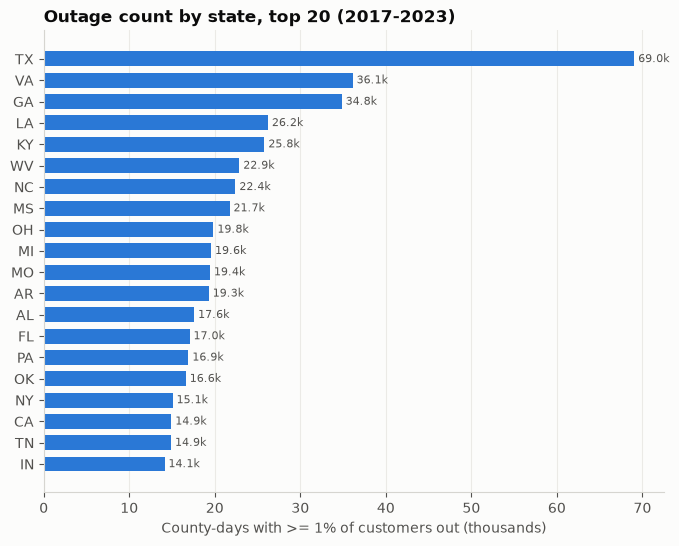

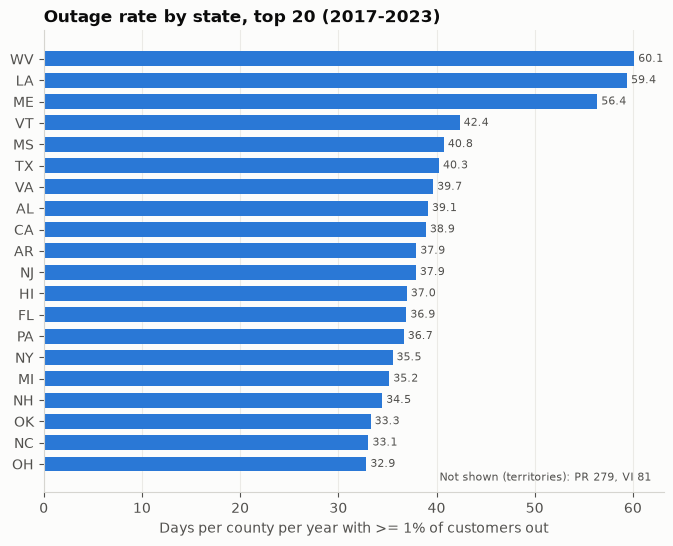

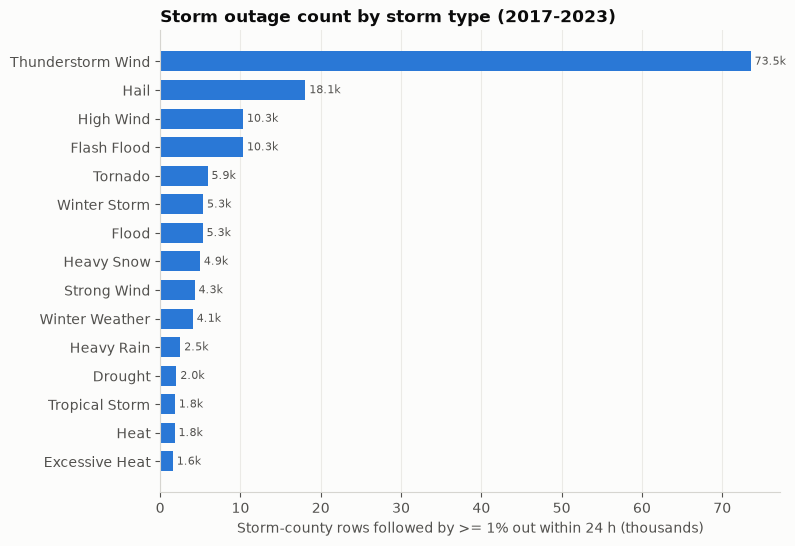

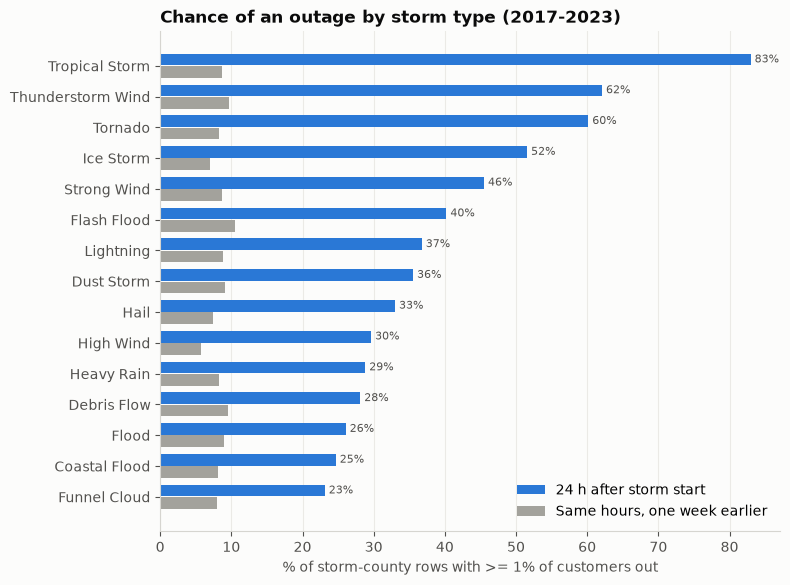

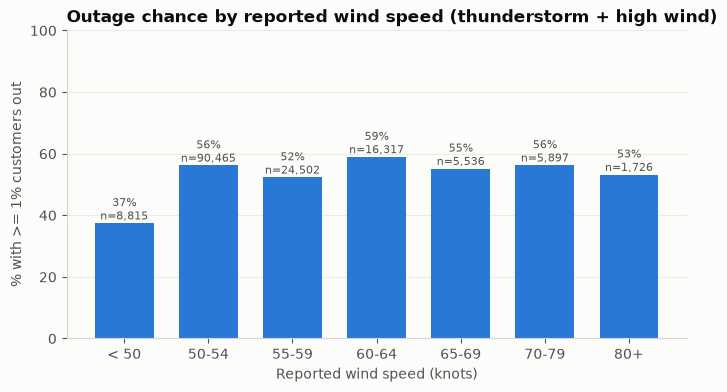

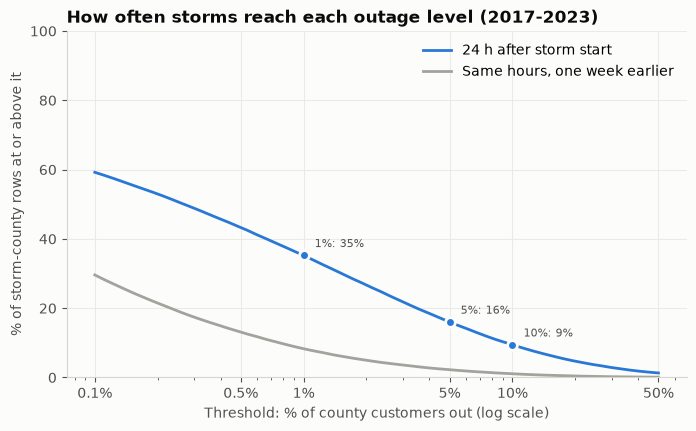

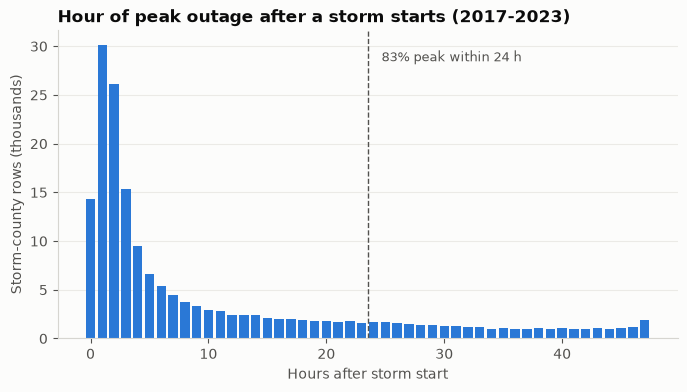

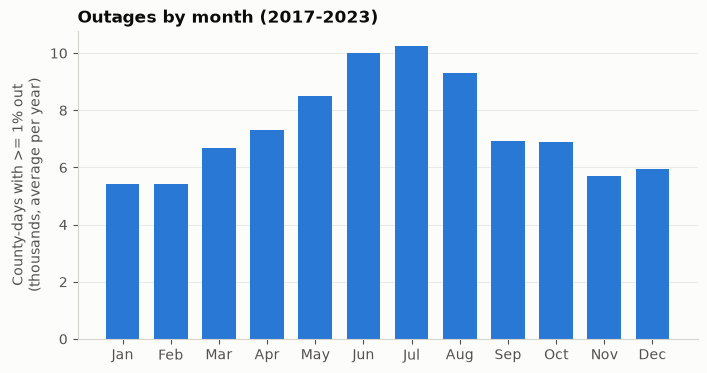

In [2]:
events = event_tables(paths)
display(events["state_days"].head(10))
display(events["by_type"].head(15))
event_charts = event_figures(events)
for chart in event_charts.values():
    display(chart)
    plt.close(chart)


The earlier severity/timing analysis motivated the 5% target and 24-hour
window. These are project choices rather than utility service standards.
The modeling label uses the hour containing the first county report; it can
include observations before the exact report minute.


## Modeling-dataset coverage and missingness

The release contains 208,482 training rows, 31,064 validation rows, and 32,098
test-feature rows. Storm intensity missingness depends strongly on report type.
Pre-storm features are unknown when the preceding day was not observed.


In [3]:
train, validation, test = load_analysis_data(paths)
tables = model_tables(train, validation, test)
display(tables["dataset_overview"])
display(tables["missingness_vs_target"])
display(tables["feature_dictionary"])


,split,years,rows,counties,episodes,states,positive_rate
0,train,2017-2023,208482,3073,54580,49,0.141278
1,validation,2024-2024,31064,3023,7734,49,0.164821
2,test,2025-2025,32098,3014,7866,49,NaN


,feature,missing_pct,rate_when_missing,rate_when_present
2,max_hurricane_cat,99.921816,0.140683,0.901840
1,max_hail_in,87.192659,0.143359,0.127111
0,max_wind_kts,59.048263,0.086284,0.220575
4,pre_peak_24h,3.321630,0.116245,0.142138
5,pct_out_at_start,3.321630,0.116245,0.142138
3,log_pop,0.362142,0.112583,0.141383


,column,group,unit,dtype,description,model_input,missing_pct_train,missing_pct_val,missing_pct_test,distinct,mean,std,min,p25,median,p75,p99,max,share_zero
0,fips,id,text,str,5-digit county FIPS code (Census 2023),False,0.000000,0.000000,0.000000,3073.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,episode_id,id,integer,int64,NOAA Storm Events EPISODE_ID (one storm system),False,0.000000,0.000000,0.000000,54580.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,state_abbr,id,text,str,State postal code (lower 48 + DC),False,0.000000,0.000000,0.000000,49.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,fema_region,id,1-10,int64,FEMA region of the county,False,0.000000,0.000000,0.000000,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,year,id,year,int64,UTC year of t0; sets the split (train 2017-202...,False,0.000000,0.000000,0.000000,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,t0,id,UTC time,datetime64[us],Begin time of the episode's first report in th...,False,0.000000,0.000000,0.000000,119453.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,n_events,storm,count,int64,Storm reports in this county during the episod...,True,0.000000,0.000000,0.000000,NaN,1.876291,2.108172,1.000000,1.000000,1.000000,2.000000,10.000000,83.000000,0.000000
7,n_tstm_wind,storm,count,int64,Reports of type Thunderstorm Wind,True,0.000000,0.000000,0.000000,NaN,0.561214,1.378355,0.000000,0.000000,0.000000,1.000000,6.000000,60.000000,0.712767
8,n_hail,storm,count,int64,Reports of type Hail,True,0.000000,0.000000,0.000000,NaN,0.257154,1.013745,0.000000,0.000000,0.000000,0.000000,4.000000,57.000000,0.871927
9,n_tornado,storm,count,int64,Reports of type Tornado or Funnel Cloud,True,0.000000,0.000000,0.000000,NaN,0.053789,0.325590,0.000000,0.000000,0.000000,0.000000,1.000000,35.000000,0.961100


## Which training inputs are associated with outages?

History and pre-storm conditions have strong individual associations. Storm
families overlap, so their rates are not mutually exclusive. These training
associations do not measure held-out predictive performance or causal effects.
The selected model's nineteen inputs are a subset of the 36 candidate features.


,feature,group,auc,strength,direction,coverage_pct,spearman
0,hist_outage_rate,history,0.738130,0.738130,higher -> more outages,100.00000,0.287323
1,hist_mean_peak,history,0.731636,0.731636,higher -> more outages,100.00000,0.279487
2,pre_peak_24h,pre-storm,0.668067,0.668067,higher -> more outages,96.67837,0.205644
3,hist_episodes,history,0.351321,0.648679,higher -> fewer outages,100.00000,-0.179398
4,episode_events,storm,0.644902,0.644902,higher -> more outages,100.00000,0.175019
5,n_tstm_wind,storm,0.637761,0.637761,higher -> more outages,100.00000,0.208973
6,pct_out_at_start,pre-storm,0.615390,0.615390,higher -> more outages,96.67837,0.159159
7,n_county_coded,storm,0.611195,0.611195,higher -> more outages,100.00000,0.144639
8,episode_counties,storm,0.585929,0.585929,higher -> more outages,100.00000,0.103872
9,log_episode_counties,storm,0.585929,0.585929,higher -> more outages,100.00000,0.103872


,family,rows,rate,rate_only_family
11,other,6909,0.034158,0.019476
8,cold,10526,0.049876,0.044245
10,wildfire,3725,0.055570,0.042469
5,winter,55210,0.076653,0.073944
9,lightning,1815,0.099174,0.051031
4,flood,29586,0.116237,0.081859
1,hail,26701,0.127111,0.069293
3,high_wind,26049,0.161580,0.149804
0,tstm_wind,59883,0.248151,0.241396
2,tornado,8110,0.290382,0.199735


,feature_a,feature_b,spearman
778,episode_counties,log_episode_counties,1.000000
1000,log_customers,log_pop,0.980263
519,n_zone_coded,share_zone_coded,0.949241
1259,hist_outage_rate,hist_mean_peak,0.943872
483,n_county_coded,share_zone_coded,-0.926854
482,n_county_coded,n_zone_coded,-0.866228
816,log_episode_counties,episode_events,0.824632
780,episode_counties,episode_events,0.824632
49,n_tstm_wind,n_county_coded,0.652921
524,n_zone_coded,county_episode_hours,0.637797


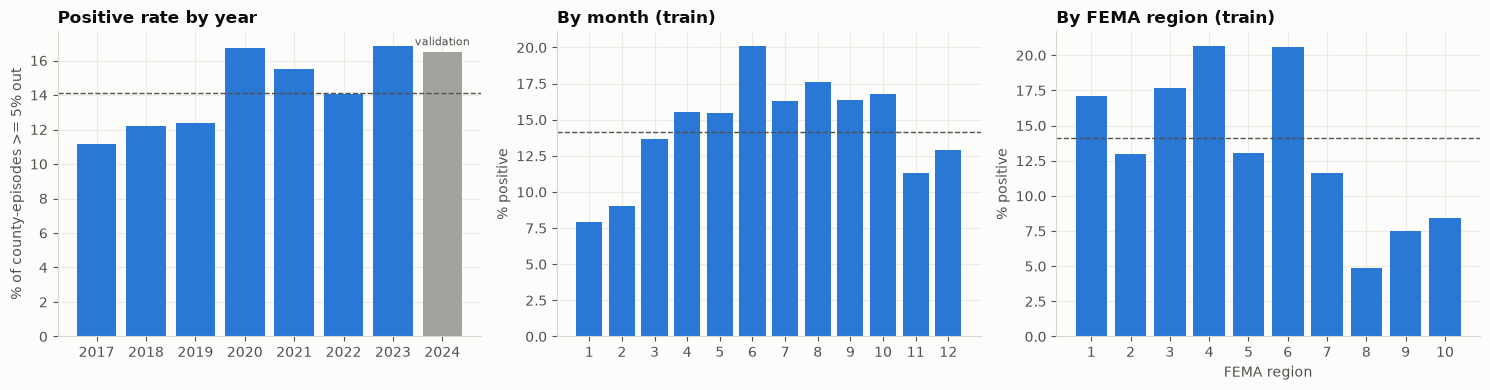

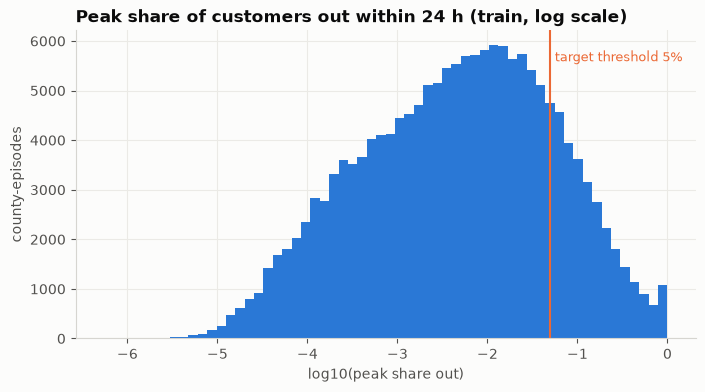

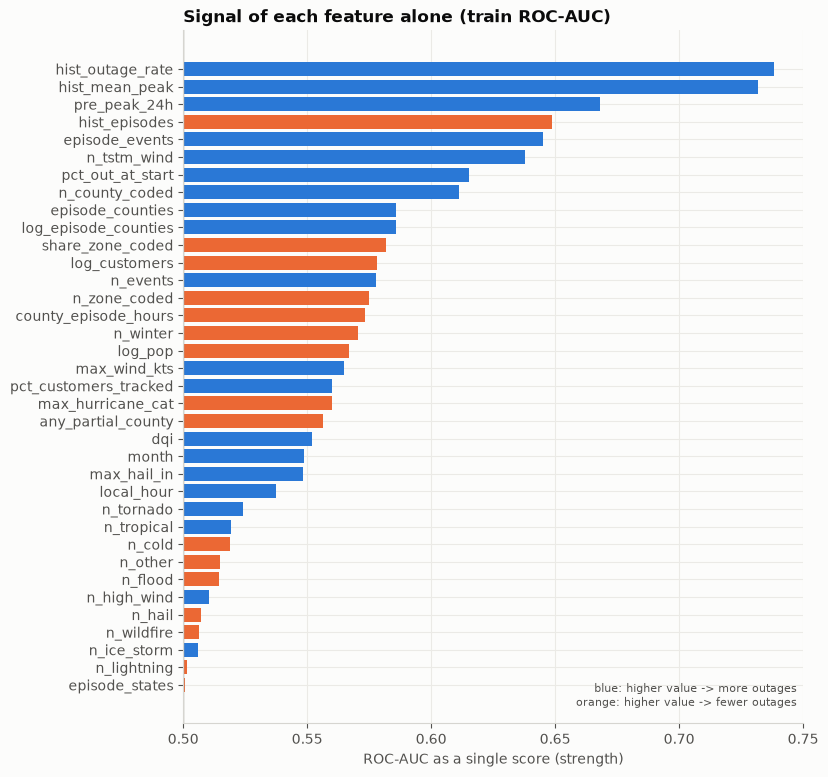

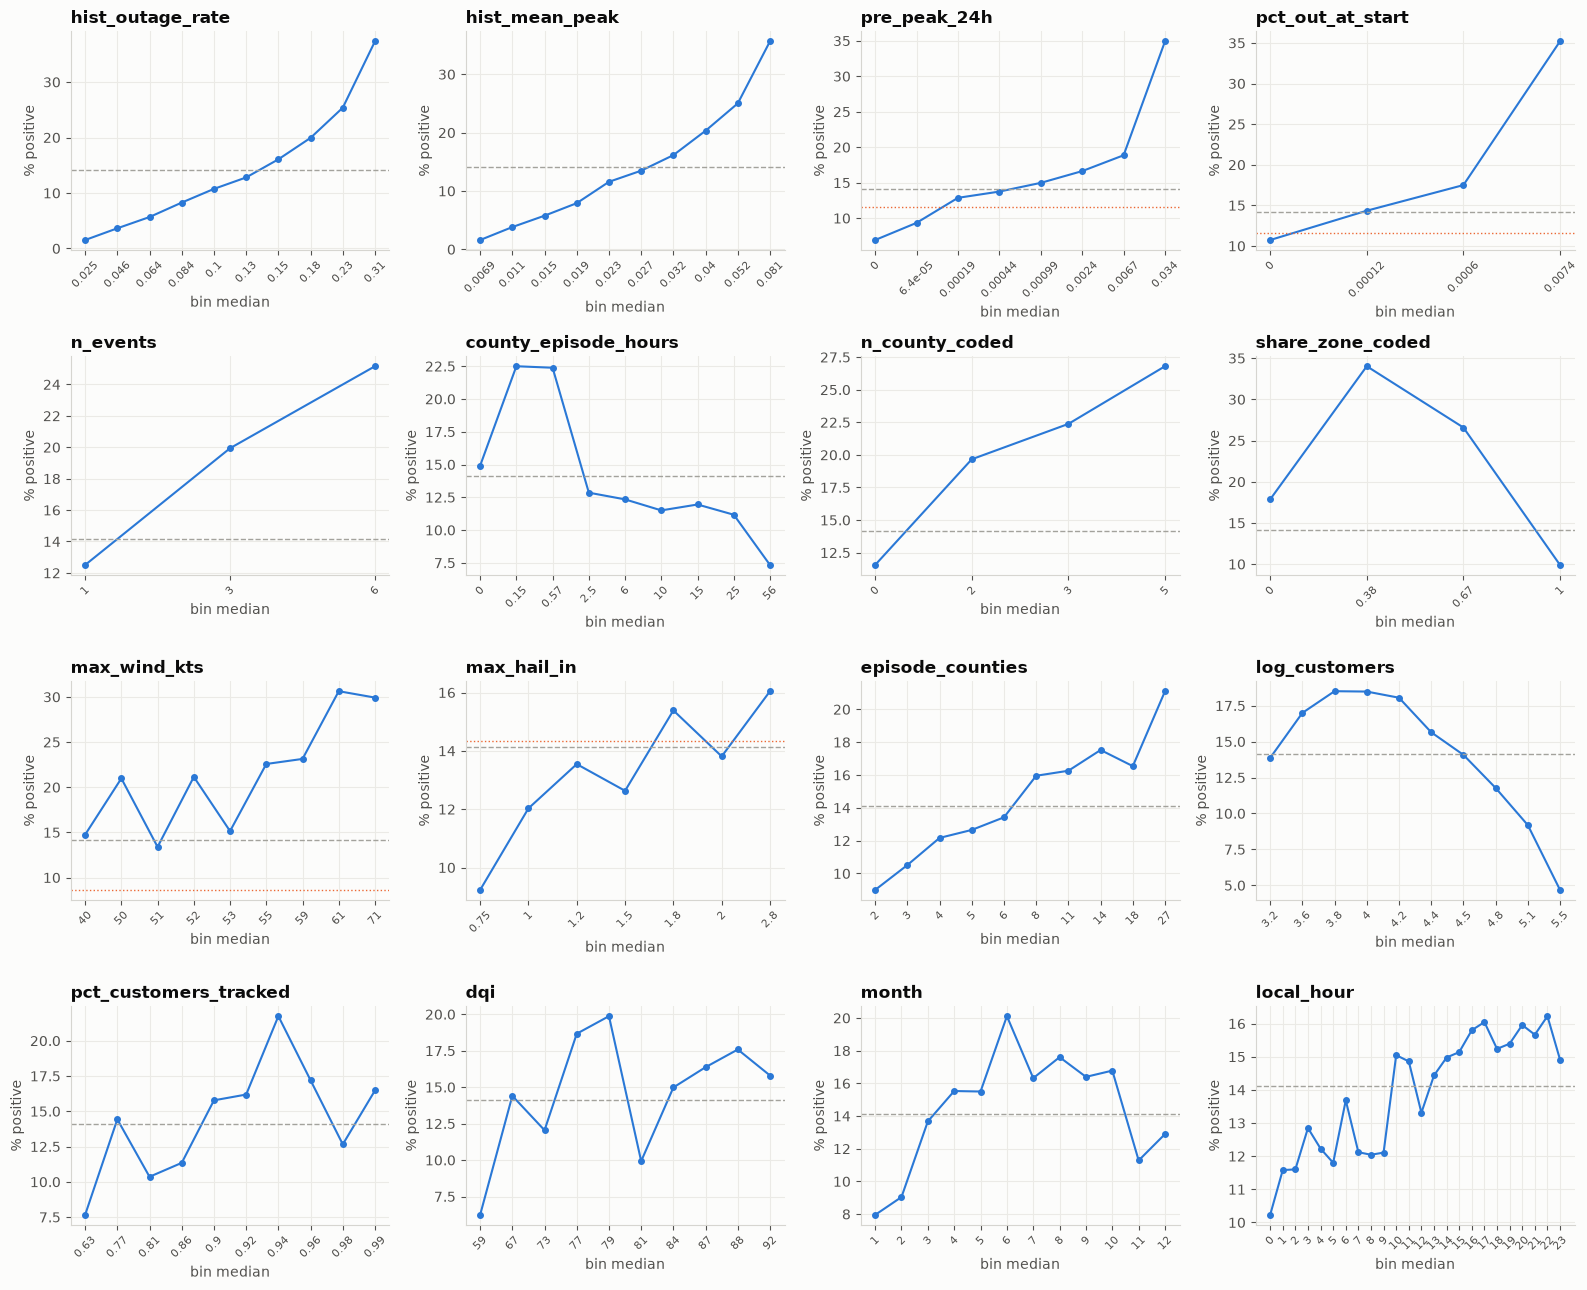

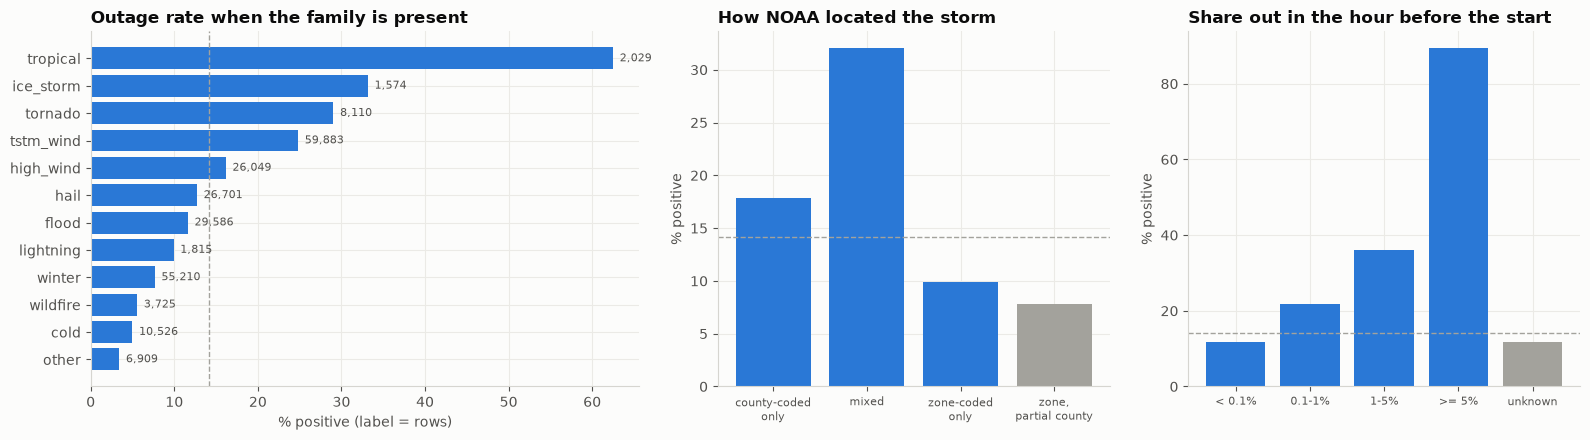

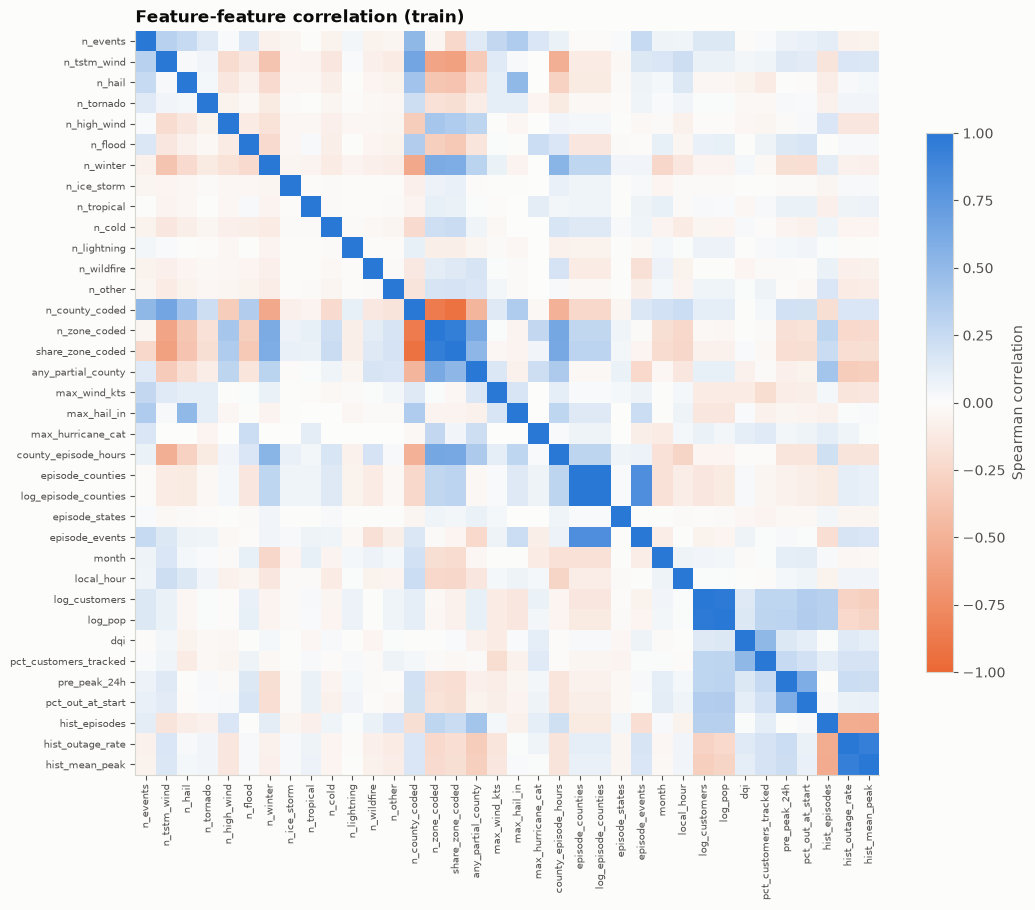

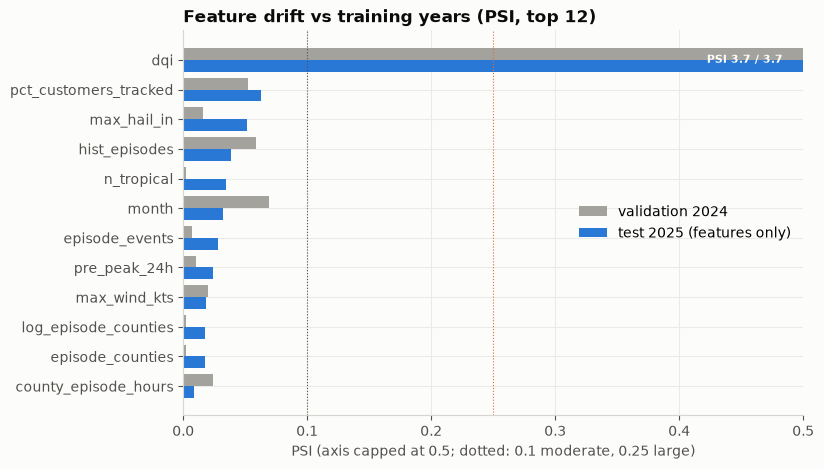

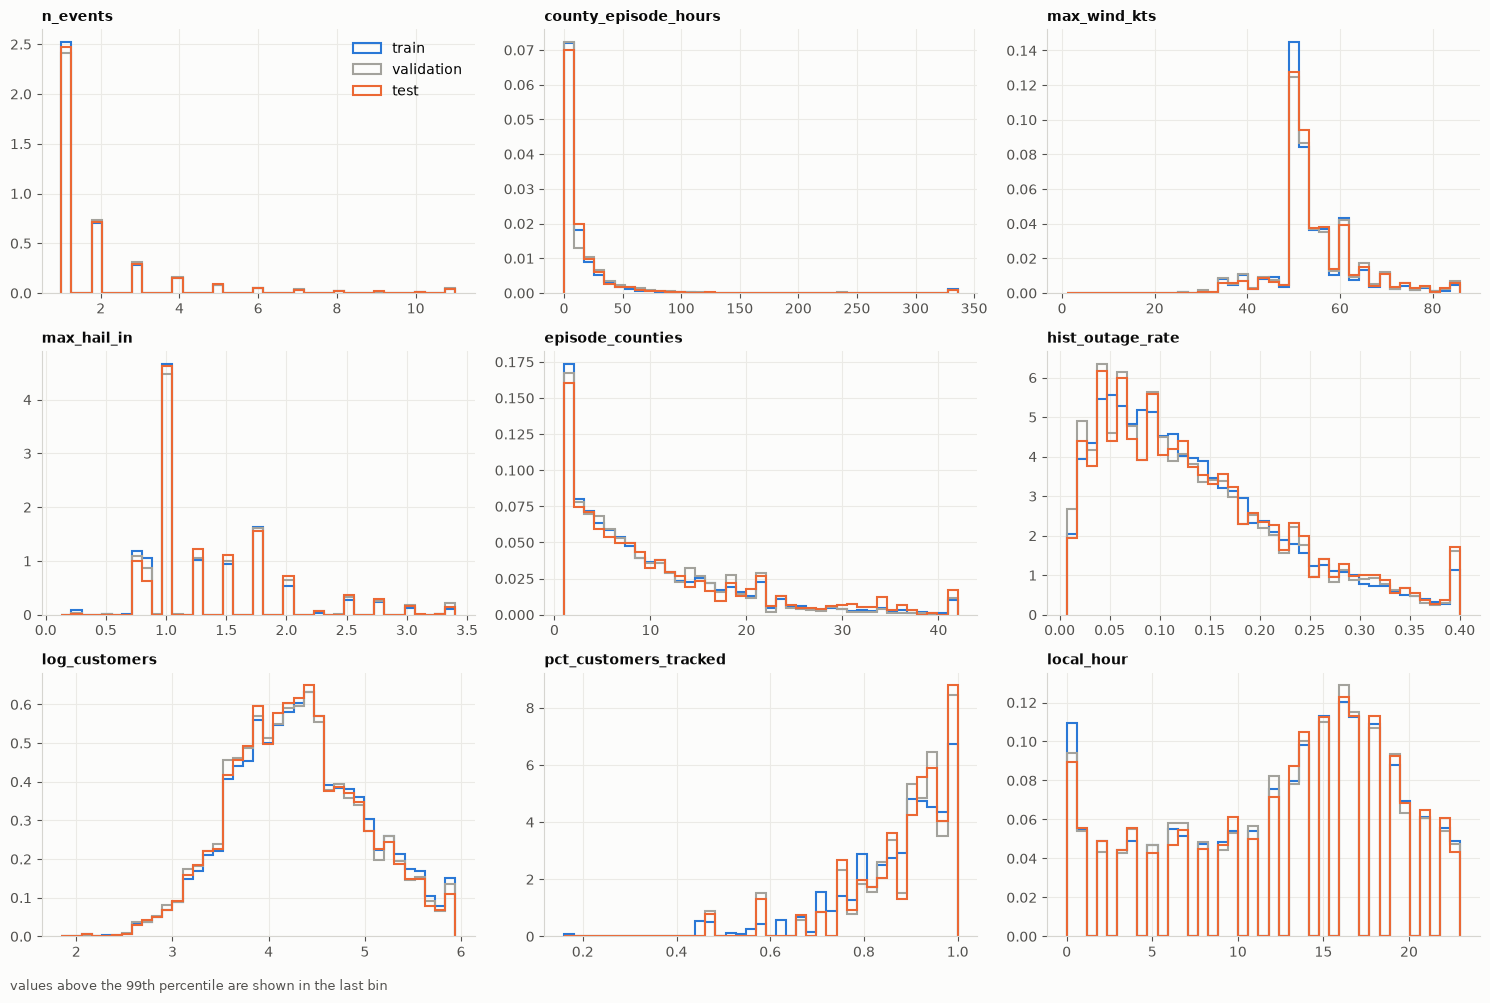

In [4]:
display(tables["univariate_signal"].head(15))
display(tables["rate_by_storm_family"])
display(tables["top_correlated_pairs"].head(12))
charts = model_figures(train, validation, test, tables)
for name in list(charts)[:6]:
    display(charts[name])
    plt.close(charts[name])


## Do feature distributions change across splits?

DQI shifts partly because its 2018–2022 reference values are mapped to nearby
years. PSI compares observed values only; if either split has no observations,
it is unavailable and missingness counts are reported separately. The extremely
sparse hurricane-category field must not be interpreted as a reliable drift estimate.


,feature,group,mean_train,observed_train,missing_train,mean_validation,observed_validation,missing_validation,psi_validation,status_validation,mean_test,observed_test,missing_test,psi_test,status_test
29,dqi,county,78.188893,208482,0,84.548004,31064,0,3.694246,available,84.776546,32098,0,3.748129,available
30,pct_customers_tracked,county,0.868135,208482,0,0.883509,31064,0,0.052527,available,0.885042,32098,0,0.062973,available
18,max_hail_in,storm,1.290097,26701,181781,1.362754,4012,27052,0.015857,available,1.368397,3849,28249,0.051275,available
33,hist_episodes,history,86.628131,208482,0,101.561679,31064,0,0.058850,available,97.180634,32098,0,0.038444,available
8,n_tropical,storm,0.012303,208482,0,0.019927,31064,0,0.002323,available,0.000280,32098,0,0.034161,available
25,month,time,5.713424,208482,0,5.405164,31064,0,0.069157,available,5.434202,32098,0,0.032232,available
24,episode_events,storm,15.460241,208482,0,16.702582,31064,0,0.007467,available,18.478067,32098,0,0.027984,available
31,pre_peak_24h,pre-storm,0.008510,201557,6925,0.009484,30940,124,0.010368,available,0.010135,31190,908,0.024297,available
17,max_wind_kts,storm,54.031952,85377,123105,54.604796,13803,17261,0.020228,available,54.834583,13608,18490,0.018757,available
22,log_episode_counties,storm,0.807479,208482,0,0.812145,31064,0,0.002525,available,0.844703,32098,0,0.017703,available


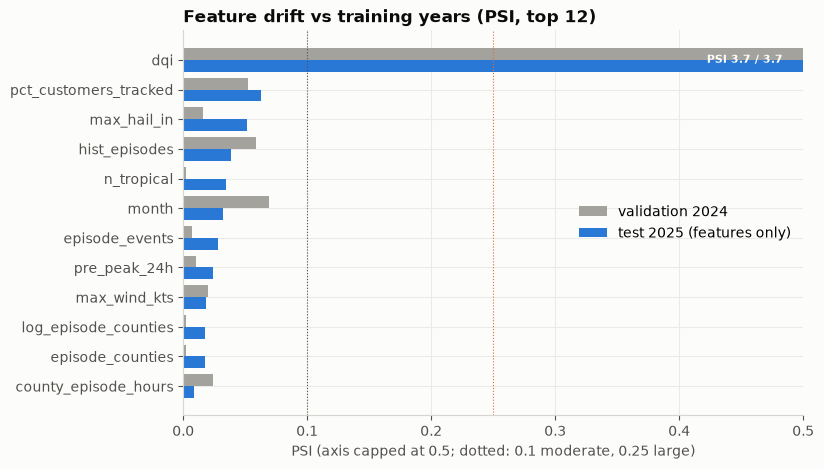

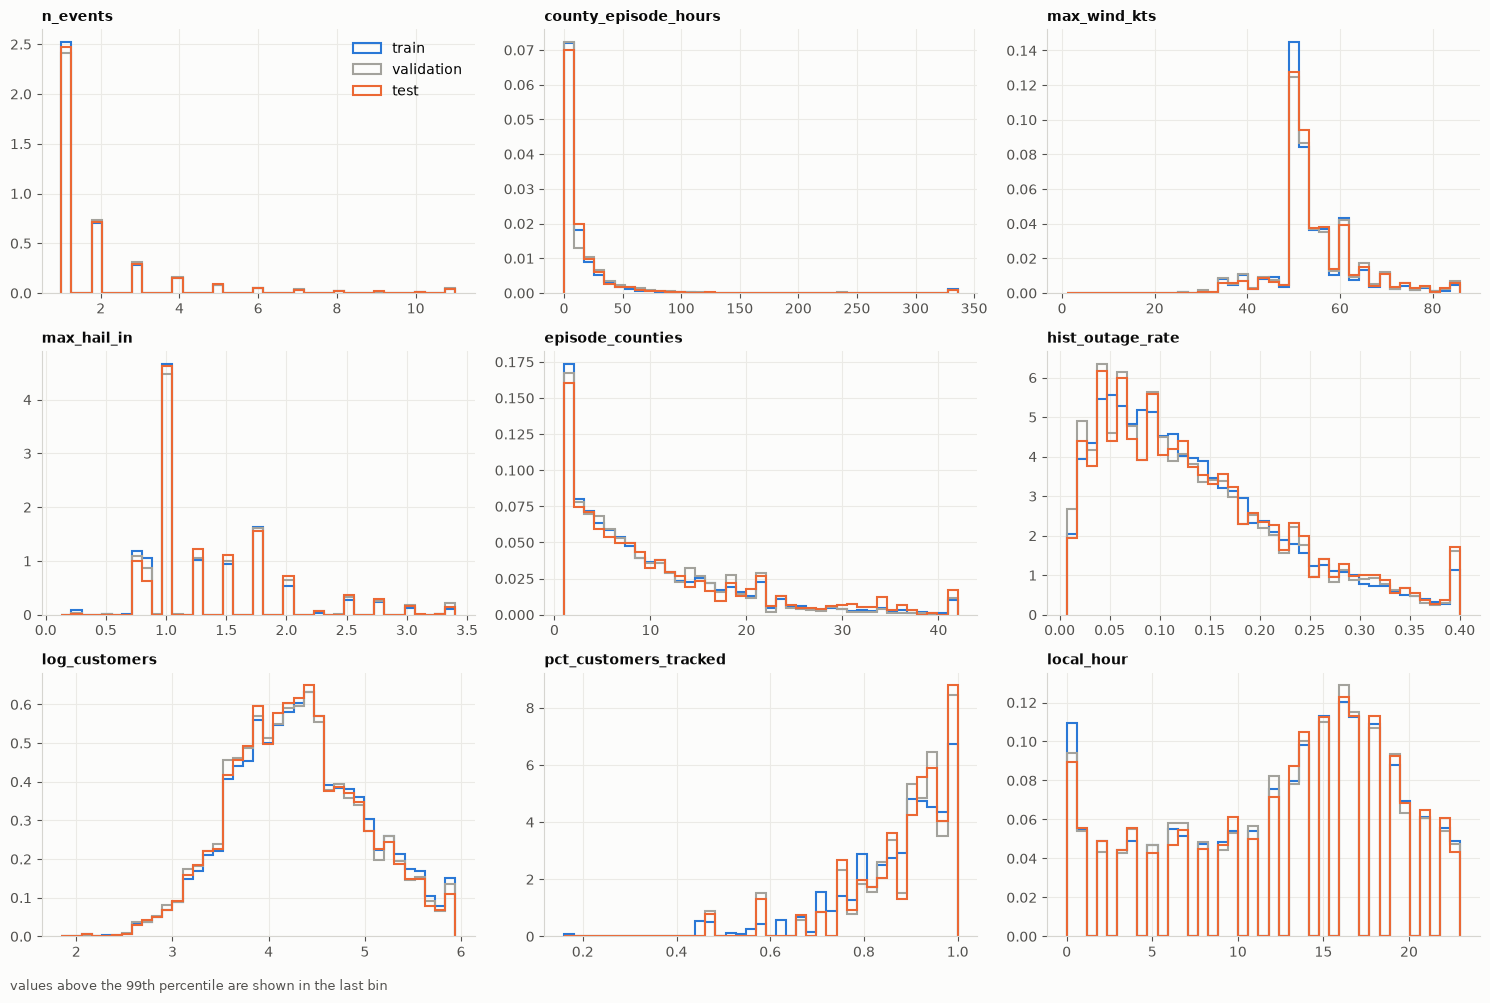

In [5]:
display(tables["feature_drift_psi"])
for name in list(charts)[6:]:
    display(charts[name])
    plt.close(charts[name])


## Interpretation and optional export

The data support retrospective model comparisons. Whole-episode counts can
include later reports, and training histories use other training years plus
full-training priors. Removing `retro_` fields does not turn this into a live
forecast dataset. Already-out counties remain eligible for positive labels.

All tables and charts above are inline. Call
`export_results(tables, charts, directory=...)` only when an external deliverable
needs them. The curated [EDA report](../reports/eda_report.md) remains available.
